# Student Support Queue: Use Limited Support Before Exams

**Decision:** Which students should a teacher contact first when support capacity is limited?

Schools can discover learning gaps only after an exam, when recovery becomes harder. A useful data product turns existing records into a short, reviewable support queue before the exam. Students receive help sooner; teachers spend their limited time on the students most likely to need it.

This notebook builds that product from `student_exam_performance.csv`. It audits the raw file, prevents outcome leakage, compares simple and richer models, tests a fixed-capacity queue, and exports a usable worklist. The endpoint is a teacher decision, not a leaderboard score.

**Outcome:** a recorded exam score below 50. This is the file's pass/fail boundary, not a universal school standard. The model does not predict dropout or diagnose a student.

**Evidence boundary:** the supplied file has no provenance, license, school identifier, subject, exam date, or feature collection times. Its patterns may come from generated data. Results describe this file; they do not establish performance in real schools or the effect of tutoring. The deployable workflow requires a verified pre-exam snapshot and prospective local evaluation.

**Run:** attach the CSV as a Kaggle input and run all cells on CPU. No internet, GPU, external notebook, or API key is required. All charts and conclusions are computed from the attached file.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

SEED = 42
SUPPORT_FRACTION = 0.10  # Assumed capacity: ten support slots per 100 students.
FAIL_SCORE = 50
DATA_PATH = None  # Set a path here only if more than one matching CSV is attached.
EXPORT_INDIVIDUAL_QUEUE = False  # Keep individual records out of public Kaggle outputs by default.
THREAD_LIMIT = threadpool_limits(limits=2)
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.dpi': 120})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 65)
OUTPUT = Path('/kaggle/working/student_support') if Path('/kaggle').exists() else Path.cwd() / 'outputs' / 'student_support'
OUTPUT.mkdir(parents=True, exist_ok=True)
versions = {'python': platform.python_version(), 'pandas': pd.__version__,
            'numpy': np.__version__, 'scikit_learn': sklearn.__version__}
print('Runtime:', versions)

Runtime: {'python': '3.12.14', 'pandas': '3.0.6', 'numpy': '2.5.3', 'scikit_learn': '1.9.1'}


## 1. Raw data and quality checks

One row is treated as one student exam record. The identifier is checked for uniqueness; a source owner must still confirm this grain. Missing measurements remain missing until preprocessing. The raw file is preserved.

In [2]:
if DATA_PATH is None:
    if Path('/kaggle/input').exists():
        candidates = sorted(Path('/kaggle/input').rglob('student_exam_performance.csv'))
    else:
        candidates = [p for p in [Path.cwd() / 'student_exam_performance.csv',
                      Path.cwd().parent / 'student_exam_performance.csv',
                      Path.cwd().parent.parent / 'student_exam_performance.csv'] if p.exists()]
    candidates = list(dict.fromkeys(p.resolve() for p in candidates))
    if len(candidates) != 1:
        raise ValueError(f'Found {len(candidates)} matching files. Set DATA_PATH explicitly.')
    DATA_PATH = candidates[0]
DATA_PATH = Path(DATA_PATH)
raw = pd.read_csv(DATA_PATH)
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f'Loaded {len(raw):,} records and {raw.shape[1]} columns.')
print('Source SHA-256:', source_hash)

assert raw.student_id.notna().all() and raw.student_id.is_unique, 'Resolve missing or repeated IDs before splitting.'
assert raw.exam_score.notna().all() and raw.exam_score.between(0, 100).all()
assert set(raw.pass_status.unique()) == {'Pass', 'Fail'}
df = raw.copy()
df['failed_exam'] = (df.exam_score < FAIL_SCORE).astype(int)
assert (df.failed_exam == df.pass_status.eq('Fail').astype(int)).all(), 'Outcome definitions disagree.'

quality = pd.DataFrame({
    'check': ['Records', 'Columns', 'Repeated complete rows', 'Repeated student IDs',
              'Records missing at least one value', 'Score / pass-status disagreements',
              'Correct answers exceed attempted answers', 'Undergraduates younger than 18'],
    'value': [len(raw), raw.shape[1], int(raw.duplicated().sum()), int(raw.student_id.duplicated().sum()),
              int(raw.isna().any(axis=1).sum()), 0,
              int((raw.questions_correct > raw.questions_attempted).sum()),
              int((raw.education_level.eq('Undergraduate') & raw.age.lt(18)).sum())]
})
display(quality)
missing = raw.isna().sum().rename('missing_records').to_frame()
missing['missing_percent'] = 100 * missing.missing_records / len(raw)
display(missing[missing.missing_records > 0].sort_values('missing_records', ascending=False).round(2))
quality.to_csv(OUTPUT / 'data_quality.csv', index=False)

Loaded 100,000 records and 44 columns.
Source SHA-256: 59194c1ecab01b34fa2486e40b9b764a09a7f3763d4886552332856b2d94598d


,check,value
0,Records,100000
1,Columns,44
2,Repeated complete rows,0
3,Repeated student IDs,0
4,Records missing at least one value,41940
5,Score / pass-status disagreements,0
6,Correct answers exceed attempted answers,0
7,Undergraduates younger than 18,23092


,missing_records,missing_percent
attendance_percentage,9863,9.86
time_management_score,9613,9.61
notes_quality,8407,8.41
previous_gpa,7793,7.79
sleep_quality,6994,6.99
parent_education,6526,6.53
device_availability,2965,2.96


The answer-count check tests internal consistency. Undergraduate age is a context check, not an automatic error: early university entry can occur. Without a source description, neither item can be repaired by assumption. Answer counts and age are excluded from prediction.

Concentrated scales, balanced categories, regular IDs, or unusual age/education combinations may warrant a provenance review. These observations do not prove that the file is synthetic. No real-school population size or national failure rate is inferred from this file.

## 2. Define the product and its data contract

**User:** a teacher or student-support coordinator. **Beneficiary:** a student who needs academic support. **Buyer:** a school or college funding support delivery.

At a planned pre-exam checkpoint, the coordinator sets available slots. The product ranks students by estimated failure risk, shows recorded support needs, and assigns a teacher to review each case. The teacher confirms learning gaps and agrees on support with the student. Unselected students retain access to ordinary support and teacher referral.

Ranking is based on risk, not expected treatment benefit. The file contains no randomized intervention outcomes, so it cannot identify who will benefit most from a particular treatment.

| Field group | Use | Timing requirement |
|---|---|---|
| Previous score, previous GPA, attendance, assignment completion | Administrative baseline | Prior exam records and cumulative records frozen before the current exam |
| Study hours, practice tests, participation, consistency, revision, notes | Optional richer model | Recorded before the checkpoint; validate availability and reliability locally |
| Current exam score, grade, pass status, performance level, answer counts | Target or excluded outcomes | Never available to the scoring function |
| Time management, anxiety, stress, exam preparation days, exam difficulty | Excluded ambiguous fields | Collection time or definition is unverified |
| Gender, age, income, parental education, location, school type, education level | Audit only | Never used to rank students; audit access and error patterns |
| Internet and device access | Support routing only | Helps choose an accessible contact/support route; does not change risk rank |
| Other behavior, wellbeing, app and tuition fields | Excluded | Not needed for the proposed minimal workflow |

The richer model is conditional on those fields being available before the exam. If they cannot be verified, use the administrative baseline after local validation. The same timing check also applies to attendance and assignments.

In [3]:
CORE = ['previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate']
RICH_NUM = CORE + ['study_hours_per_day', 'self_study_hours', 'practice_tests_completed']
RICH_CAT = ['class_participation', 'study_consistency', 'revision_frequency', 'notes_quality']
RICH = RICH_NUM + RICH_CAT
OUTCOME_FIELDS = ['exam_score', 'performance_grade', 'pass_status', 'performance_level',
                  'questions_attempted', 'questions_correct']
AUDIT_FIELDS = ['age', 'gender', 'education_level', 'school_type', 'family_income',
                'parent_education', 'urban_rural']
ROUTING_FIELDS = ['internet_access', 'device_availability']
assert not set(RICH).intersection(OUTCOME_FIELDS + AUDIT_FIELDS + ROUTING_FIELDS)
assert set(RICH + ROUTING_FIELDS + AUDIT_FIELDS).issubset(df.columns)

def column_role(c):
    if c == 'student_id': return 'Identifier only'
    if c in OUTCOME_FIELDS: return 'Outcome or current-exam leakage: excluded from features'
    if c in CORE: return 'Administrative predictor: pre-exam timing required'
    if c in RICH: return 'Optional study predictor: pre-exam timing required'
    if c in AUDIT_FIELDS: return 'Group audit only'
    if c in ROUTING_FIELDS: return 'Accessible support routing only'
    return 'Excluded: ambiguous timing or unnecessary collection'

dictionary = pd.DataFrame([{'column': c, 'type': str(raw[c].dtype),
    'missing_percent': round(100 * raw[c].isna().mean(), 2),
    'unique_values': raw[c].nunique(), 'product_role': column_role(c)} for c in raw.columns])
dictionary.to_csv(OUTPUT / 'data_dictionary.csv', index=False)
display(dictionary[dictionary.column.isin(RICH + OUTCOME_FIELDS)])

,column,type,missing_percent,unique_values,product_role
8,previous_exam_score,float64,0.00,6153,Administrative predictor: pre-exam timing required
9,previous_gpa,float64,7.79,296,Administrative predictor: pre-exam timing required
10,attendance_percentage,float64,9.86,3911,Administrative predictor: pre-exam timing required
11,assignment_completion_rate,float64,0.00,6384,Administrative predictor: pre-exam timing required
12,class_participation,str,0.00,3,Optional study predictor: pre-exam timing required
13,study_hours_per_day,float64,0.00,1073,Optional study predictor: pre-exam timing required
14,self_study_hours,float64,0.00,856,Optional study predictor: pre-exam timing required
17,study_consistency,str,0.00,3,Optional study predictor: pre-exam timing required
20,revision_frequency,str,0.00,3,Optional study predictor: pre-exam timing required
21,practice_tests_completed,int64,0.00,21,Optional study predictor: pre-exam timing required


## 3. Hold out outcomes before learning patterns

The split is fixed at 60% training, 10% probability calibration, 10% model selection, and 20% final testing. Preprocessing learns from training records only. Calibration learns from its separate split. Model selection uses precision at the assumed 10% capacity. Final test outcomes are opened only after the model and decision policy are frozen.

There are no dates or school IDs. This is a stratified random holdout, not a test on future exams or unseen schools. A local pilot must use later exams and school-level separation when relevant. This notebook does not claim temporal validation.

In [4]:
y = df.failed_exam
train_i, rest_i = train_test_split(df.index.to_numpy(), test_size=0.40, stratify=y, random_state=SEED)
cal_i, remaining_i = train_test_split(rest_i, train_size=0.25, stratify=y.loc[rest_i], random_state=SEED + 1)
val_i, test_i = train_test_split(remaining_i, train_size=1/3, stratify=y.loc[remaining_i], random_state=SEED + 2)
split_sets = [set(x) for x in [train_i, cal_i, val_i, test_i]]
assert sum(map(len, split_sets)) == len(df)
assert all(not split_sets[a].intersection(split_sets[b]) for a in range(4) for b in range(a + 1, 4))
split_summary = pd.DataFrame({'split': ['Training', 'Calibration', 'Selection', 'Final test'],
                             'records': list(map(len, [train_i, cal_i, val_i, test_i]))})
display(split_summary)
train = df.loc[train_i].copy()

,split,records
0,Training,60000
1,Calibration,10000
2,Selection,10000
3,Final test,20000


## 4. What the training data says

The following descriptions use training records. Group differences and correlations are associations; they do not show what would happen if a student changed a habit. Product actions are questions for a teacher to investigate, not prescriptions derived from a correlation.

Training records below 50: 13,567 / 60,000 (22.6%)


,Correlation with failure
previous_exam_score,-0.360
previous_gpa,-0.340
study_hours_per_day,-0.224
self_study_hours,-0.210
practice_tests_completed,-0.203
assignment_completion_rate,-0.148
attendance_percentage,-0.128


,students,failure_rate
previous_exam_score,,
Below 50,2636,0.637
50 to <60,9592,0.431
60 to <70,18847,0.257
70 to <80,18141,0.131
80 to 100,10784,0.050


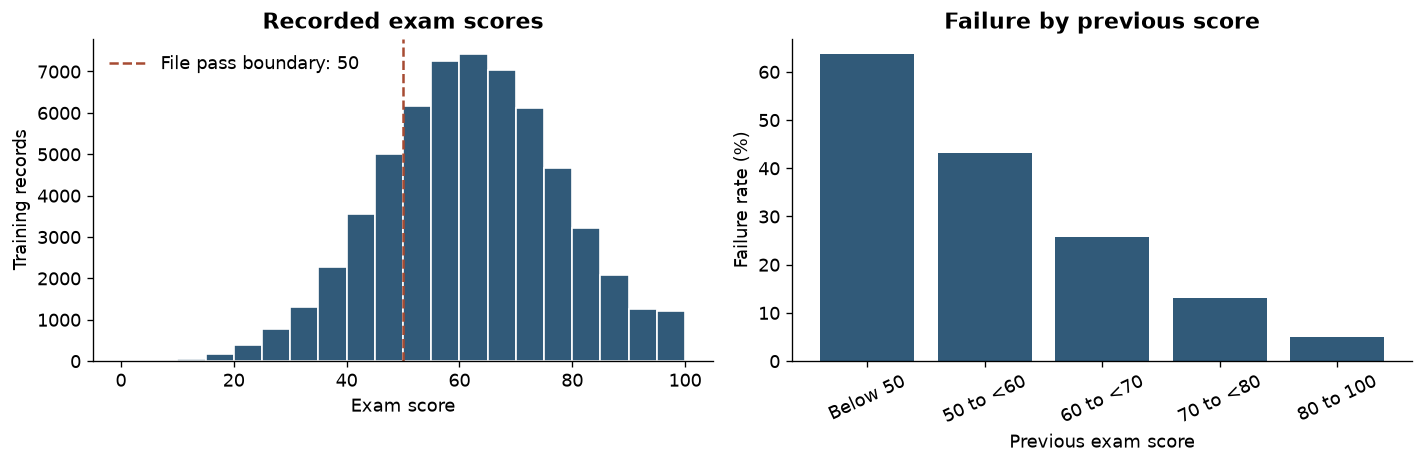

,students,failure_rate
access_issue,,
False,41205,0.226
True,18795,0.227


**Operational insight:** 31.3% of training records indicate no internet or a shared device. Offer an in-person or printed route when the student confirms that need. Access is a delivery constraint even when it adds little predictive signal. Missing device status requires a question, not an assumption.

In [5]:
train_prevalence = train.failed_exam.mean()
print(f'Training records below 50: {int(train.failed_exam.sum()):,} / {len(train):,} ({train_prevalence:.1%})')
association = train[RICH_NUM + ['failed_exam']].corr()['failed_exam'].drop('failed_exam').sort_values()
display(association.rename('Correlation with failure').round(3).to_frame())
bands = pd.cut(train.previous_exam_score, bins=[0, 50, 60, 70, 80, 100], right=False,
               labels=['Below 50', '50 to <60', '60 to <70', '70 to <80', '80 to 100'])
bands = bands.astype(object).where(train.previous_exam_score.lt(100), '80 to 100')
band_rates = train.groupby(bands, observed=True).failed_exam.agg(['size', 'mean'])
band_rates = band_rates.reindex(['Below 50', '50 to <60', '60 to <70', '70 to <80', '80 to 100'])
display(band_rates.rename(columns={'size': 'students', 'mean': 'failure_rate'}).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(train.exam_score, bins=np.arange(0, 105, 5), color='#315a79', edgecolor='white')
ax[0].axvline(FAIL_SCORE, color='#a64b32', linestyle='--', label='File pass boundary: 50')
ax[0].set(title='Recorded exam scores', xlabel='Exam score', ylabel='Training records')
ax[0].legend(frameon=False)
ax[1].bar(band_rates.index, 100 * band_rates['mean'], color='#315a79')
ax[1].set(title='Failure by previous score', xlabel='Previous exam score', ylabel='Failure rate (%)')
ax[1].tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(OUTPUT / 'training_patterns.png', bbox_inches='tight')
plt.show()

access = train.assign(access_issue=(train.internet_access.eq(0) | train.device_availability.eq('Shared')))
access_summary = access.groupby('access_issue').failed_exam.agg(['size', 'mean'])
display(access_summary.rename(columns={'size': 'students', 'mean': 'failure_rate'}).round(3))
display(Markdown(f'**Operational insight:** {access.access_issue.mean():.1%} of training records indicate no internet or a shared device. Offer an in-person or printed route when the student confirms that need. Access is a delivery constraint even when it adds little predictive signal. Missing device status requires a question, not an assumption.'))

## 5. Compare models that can make the same decision

The baselines are meaningful alternatives: random allocation as an expected benchmark, lowest previous score first, a calibrated previous-score model, and an administrative-record model. The richer candidates add only study measurements specified in the contract.

Each learned candidate uses median numeric imputation, numeric missing indicators, and most-frequent categorical imputation. Logistic models standardize numeric inputs. One-hot categories are learned only from training records. Gradient boosting models nonlinear relationships. No class weighting or oversampling changes the observed event rate.

Each candidate receives separate sigmoid calibration. There is no hyperparameter search. Selection favors precision at the fixed capacity; Brier score breaks ties. ROC AUC measures overall ranking, average precision measures ranking of failures, and Brier/log loss assess probabilities. Accuracy is not the main measure because a majority-class prediction would miss every failure.

In [6]:
def build_pipeline(numeric, categorical, nonlinear=False):
    num_steps = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
    if not nonlinear:
        num_steps.append(('scale', StandardScaler()))
    transforms = [('numeric', Pipeline(num_steps), numeric)]
    if categorical:
        transforms.append(('category', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical))
    prep = ColumnTransformer(transforms, remainder='drop')
    estimator = (HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08,
                    max_leaf_nodes=15, min_samples_leaf=50, l2_regularization=1,
                    early_stopping=False, random_state=SEED)
                 if nonlinear else LogisticRegression(max_iter=1000, C=1))
    return Pipeline([('prepare', prep), ('model', estimator)])

def logit_feature(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

def predict_bundle(bundle, frame):
    p = bundle['pipeline'].predict_proba(frame[bundle['features']])[:, 1]
    return bundle['calibrator'].predict_proba(logit_feature(p))[:, 1]

def selected_mask(scores, ids, fraction):
    if not 0 < fraction <= 1:
        raise ValueError('Capacity fraction must be greater than zero and at most one.')
    k = min(len(scores), max(1, math.ceil(len(scores) * fraction)))
    # Sorting by stable ID breaks exact score ties reproducibly.
    order = np.lexsort((np.asarray(ids).astype(str), -np.asarray(scores)))
    mask = np.zeros(len(scores), dtype=bool)
    mask[order[:k]] = True
    return mask

def queue_metrics(labels, scores, ids, fraction=SUPPORT_FRACTION):
    labels = np.asarray(labels)
    mask = selected_mask(scores, ids, fraction)
    tp = int(labels[mask].sum())
    nfail = int(labels.sum())
    base = labels.mean()
    return {'slots': int(mask.sum()), 'failures_in_queue': tp,
            'nonfailures_in_queue': int(mask.sum()) - tp,
            'failures_outside_queue': nfail - tp,
            'precision_at_capacity': tp / mask.sum(),
            'recall_at_capacity': tp / nfail if nfail else np.nan,
            'lift_over_random': (tp / mask.sum()) / base if base else np.nan}

specs = {
    'Previous-score logistic': (['previous_exam_score'], [], False),
    'Administrative logistic': (CORE, [], False),
    'Study-record logistic': (RICH_NUM, RICH_CAT, False),
    'Study-record gradient boosting': (RICH_NUM, RICH_CAT, True)
}
bundles, selection_rows, fit_times = {}, [], {}
for name, (numeric, categorical, nonlinear) in specs.items():
    t0 = time.perf_counter()
    features = numeric + categorical
    pipeline = build_pipeline(numeric, categorical, nonlinear)
    pipeline.fit(df.loc[train_i, features], y.loc[train_i])
    pcal = pipeline.predict_proba(df.loc[cal_i, features])[:, 1]
    calibrator = LogisticRegression(C=100, max_iter=1000)
    calibrator.fit(logit_feature(pcal), y.loc[cal_i])
    bundles[name] = {'pipeline': pipeline, 'calibrator': calibrator, 'features': features}
    pval = predict_bundle(bundles[name], df.loc[val_i])
    fit_times[name] = time.perf_counter() - t0
    selection_rows.append({'model': name,
        **queue_metrics(y.loc[val_i], pval, df.loc[val_i, 'student_id']),
        'roc_auc': roc_auc_score(y.loc[val_i], pval),
        'average_precision': average_precision_score(y.loc[val_i], pval),
        'brier_score': brier_score_loss(y.loc[val_i], pval),
        'log_loss': log_loss(y.loc[val_i], pval), 'fit_seconds': fit_times[name]})

selection = pd.DataFrame(selection_rows).set_index('model')
selected_name = selection.sort_values(['precision_at_capacity', 'brier_score'], ascending=[False, True]).index[0]
champion = bundles[selected_name]
simple_name = 'Administrative logistic'
selection.to_csv(OUTPUT / 'model_selection.csv')
display(selection[['precision_at_capacity', 'recall_at_capacity', 'roc_auc',
                   'average_precision', 'brier_score', 'fit_seconds']].round(4))
print('Frozen model:', selected_name)
print(f'Frozen capacity: {SUPPORT_FRACTION:.0%}; frozen outcome: score below {FAIL_SCORE}.')

,precision_at_capacity,recall_at_capacity,roc_auc,average_precision,brier_score,fit_seconds
model,,,,,,
Previous-score logistic,0.528,0.2335,0.7392,0.4574,0.1519,0.0299
Administrative logistic,0.586,0.2592,0.7569,0.4876,0.1477,0.0464
Study-record logistic,0.681,0.3012,0.8143,0.5768,0.1332,0.1311
Study-record gradient boosting,0.680,0.3008,0.8128,0.5748,0.1336,0.8214


Frozen model: Study-record logistic
Frozen capacity: 10%; frozen outcome: score below 50.


## 6. Explain the ranking without claiming a cause

Permutation importance measures how much selection-set average precision drops when one input is shuffled. It explains reliance on a field across records, not why a specific student will fail. Correlated inputs can share importance; a small value does not prove the input is unimportant educationally. Selection-set explanations are not used to change the frozen model.

,feature,average_precision_drop,repeat_sd
0,previous_exam_score,0.2877,0.0093
4,study_hours_per_day,0.1049,0.0038
6,practice_tests_completed,0.0559,0.0053
2,attendance_percentage,0.0371,0.0062
10,notes_quality,0.0003,0.0002
5,self_study_hours,-0.0003,0.0013
7,class_participation,-0.0004,0.0003
8,study_consistency,-0.0005,0.0005
3,assignment_completion_rate,-0.0007,0.0003
9,revision_frequency,-0.0011,0.0004


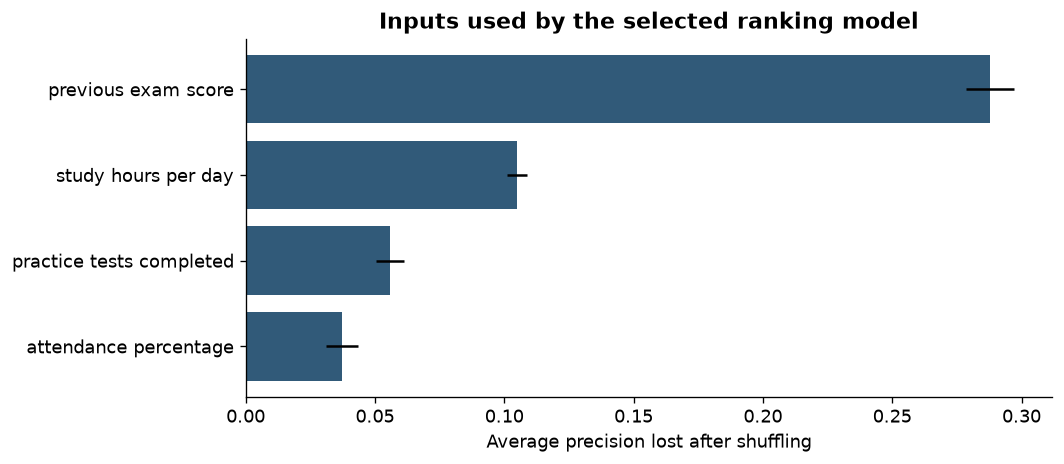

**Decision insight:** inspect the importance table before expanding data collection. Fields with little incremental ranking value may still help a teacher understand support needs. A future pilot should test whether a smaller feature set gives comparable reach at lower collection cost. Changing study hours or practice-test counts is not a proven treatment effect.

In [7]:
class ProbabilityAdapter:
    # A public predict_proba interface lets sklearn score the calibrated bundle.
    def __init__(self, bundle):
        self.bundle = bundle
        self.classes_ = np.array([0, 1])
    def fit(self, X, y=None):
        return self
    def predict_proba(self, X):
        p = predict_bundle(self.bundle, X)
        return np.column_stack([1 - p, p])

explain_i = df.loc[val_i].sample(n=min(3000, len(val_i)), random_state=SEED).index
def ap_scorer(estimator, X, labels):
    return average_precision_score(labels, estimator.predict_proba(X)[:, 1])
importance = permutation_importance(ProbabilityAdapter(champion),
    df.loc[explain_i, champion['features']], y.loc[explain_i],
    scoring=ap_scorer, n_repeats=3, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'feature': champion['features'],
    'average_precision_drop': importance.importances_mean,
    'repeat_sd': importance.importances_std}).sort_values('average_precision_drop', ascending=False)
display(importance_table.round(4))
importance_table.to_csv(OUTPUT / 'feature_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
top = importance_table.head(4).iloc[::-1]
ax.barh(top.feature.str.replace('_', ' '), top.average_precision_drop, color='#315a79', xerr=top.repeat_sd)
ax.set(title='Inputs used by the selected ranking model', xlabel='Average precision lost after shuffling')
fig.tight_layout()
fig.savefig(OUTPUT / 'feature_importance.png', bbox_inches='tight')
plt.show()
display(Markdown('**Decision insight:** inspect the importance table before expanding data collection. Fields with little incremental ranking value may still help a teacher understand support needs. A future pilot should test whether a smaller feature set gives comparable reach at lower collection cost. Changing study hours or practice-test counts is not a proven treatment effect.'))

## 7. Final test: who is reached with the same number of slots?

The frozen model is now evaluated once on final test outcomes. A slot is a contact/support opportunity, not a prevented failure. A student who passes without the program may still benefit from support. A failure outside the queue is a missed opportunity and is reported explicitly.

Random allocation is shown as an analytic expectation. The prior-score rule ranks lower previous scores first, using the same ID tie-breaker. The administrative baseline shows whether collecting study information adds enough value to justify the work.

In [8]:
test = df.loc[test_i].copy()
test_y = test.failed_exam.to_numpy()
test_p = predict_bundle(champion, test)
simple_p = predict_bundle(bundles[simple_name], test)
prior_rank = -test.previous_exam_score.to_numpy()
test_ids = test.student_id.to_numpy()
policy_scores = {'Lowest previous score first': prior_rank,
                 'Administrative logistic': simple_p,
                 'Selected model': test_p}
test_policy = pd.DataFrame([{'policy': name, **queue_metrics(test_y, scores, test_ids)}
                           for name, scores in policy_scores.items()]).set_index('policy')
k = int(test_policy.loc['Selected model', 'slots'])
random_expected = {'slots': k, 'failures_in_queue': k * test_y.mean(),
                   'nonfailures_in_queue': k * (1 - test_y.mean()),
                   'failures_outside_queue': test_y.sum() - k * test_y.mean(),
                   'precision_at_capacity': test_y.mean(), 'recall_at_capacity': k / len(test),
                   'lift_over_random': 1.0}
test_policy.loc['Random allocation (expected)'] = random_expected
display(test_policy.round(4))
test_policy.to_csv(OUTPUT / 'heldout_policy_comparison.csv')
probability_metrics = pd.DataFrame([
    {'model': 'Selected model', 'roc_auc': roc_auc_score(test_y, test_p),
     'average_precision': average_precision_score(test_y, test_p),
     'brier_score': brier_score_loss(test_y, test_p), 'log_loss': log_loss(test_y, test_p)},
    {'model': 'Constant training prevalence', 'roc_auc': 0.5,
     'average_precision': test_y.mean(),
     'brier_score': brier_score_loss(test_y, np.full(len(test), train_prevalence)),
     'log_loss': log_loss(test_y, np.full(len(test), train_prevalence))}]).set_index('model')
display(probability_metrics.round(4))
probability_metrics.to_csv(OUTPUT / 'heldout_probability_metrics.csv')

,slots,failures_in_queue,nonfailures_in_queue,failures_outside_queue,precision_at_capacity,recall_at_capacity,lift_over_random
policy,,,,,,,
Lowest previous score first,2000,1091.0,909.0,3431.0,0.5455,0.2413,2.4126
Administrative logistic,2000,1162.0,838.0,3360.0,0.5810,0.2570,2.5697
Selected model,2000,1353.0,647.0,3169.0,0.6765,0.2992,2.9920
Random allocation (expected),2000,452.2,1547.8,4069.8,0.2261,0.1000,1.0000


,roc_auc,average_precision,brier_score,log_loss
model,,,,
Selected model,0.8177,0.5706,0.1329,0.4122
Constant training prevalence,0.5000,0.2261,0.1750,0.5345


,95% lower,95% upper
Queue precision,0.6570,0.6965
Failure recall,0.2905,0.3084
Precision gain over administrative baseline,0.0775,0.1155


,capacity,policy,precision_at_capacity,recall_at_capacity
0,0.05,Lowest previous score first,0.625,0.138
1,0.05,Administrative logistic,0.650,0.144
2,0.05,Selected model,0.734,0.162
3,0.10,Lowest previous score first,0.546,0.241
4,0.10,Administrative logistic,0.581,0.257
5,0.10,Selected model,0.676,0.299
6,0.15,Lowest previous score first,0.506,0.335
7,0.15,Administrative logistic,0.536,0.355
8,0.15,Selected model,0.619,0.411
9,0.20,Lowest previous score first,0.470,0.416


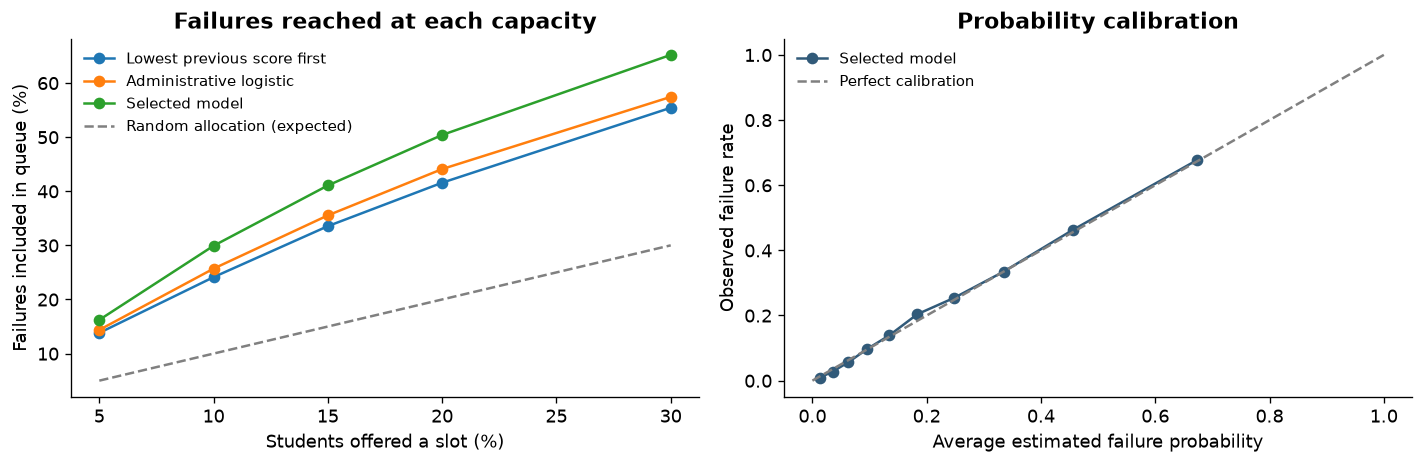

In [9]:
# Paired record bootstrap: reapply the fixed capacity in every resample.
# Intervals reflect heldout sampling uncertainty, not school/time shift or retraining uncertainty.
rng = np.random.default_rng(SEED)
boot = []
for _ in range(400):
    ix = rng.integers(0, len(test), len(test))
    ids_boot = np.array([f'{i:06d}' for i in range(len(ix))])
    m = queue_metrics(test_y[ix], test_p[ix], ids_boot)
    b = queue_metrics(test_y[ix], simple_p[ix], ids_boot)
    boot.append([m['precision_at_capacity'], m['recall_at_capacity'],
                 m['precision_at_capacity'] - b['precision_at_capacity']])
ci_values = np.quantile(np.array(boot), [0.025, 0.975], axis=0)
intervals = pd.DataFrame(ci_values.T, index=['Queue precision', 'Failure recall',
    'Precision gain over administrative baseline'], columns=['95% lower', '95% upper'])
display(intervals.round(4))
intervals.to_csv(OUTPUT / 'heldout_bootstrap_intervals.csv')

capacity_rows = []
for fraction in [0.05, 0.10, 0.15, 0.20, 0.30]:
    for name, scores in policy_scores.items():
        capacity_rows.append({'capacity': fraction, 'policy': name,
                             **queue_metrics(test_y, scores, test_ids, fraction)})
capacity_table = pd.DataFrame(capacity_rows)
capacity_table.to_csv(OUTPUT / 'capacity_sensitivity.csv', index=False)
display(capacity_table[['capacity', 'policy', 'precision_at_capacity', 'recall_at_capacity']].round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, group in capacity_table.groupby('policy', sort=False):
    ax[0].plot(100 * group.capacity, 100 * group.recall_at_capacity, marker='o', label=name)
ax[0].plot([5, 30], [5, 30], linestyle='--', color='gray', label='Random allocation (expected)')
ax[0].set(title='Failures reached at each capacity', xlabel='Students offered a slot (%)', ylabel='Failures included in queue (%)')
ax[0].legend(frameon=False, fontsize=9)
observed, predicted = calibration_curve(test_y, test_p, n_bins=10, strategy='quantile')
ax[1].plot(predicted, observed, marker='o', color='#315a79', label='Selected model')
ax[1].plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax[1].set(title='Probability calibration', xlabel='Average estimated failure probability', ylabel='Observed failure rate')
ax[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT / 'capacity_and_calibration.png', bbox_inches='tight')
plt.show()

Capacity sensitivity describes the frozen ranking at different staffing levels. It does not choose a new policy using test outcomes. Capacity should come from available staff time and student needs.

## 8. Check access and errors across groups

Protected and socioeconomic fields are excluded from risk scoring. This alone does not establish fairness: other features can act as proxies. The audit reports selection rate, failure prevalence, recall among failures, and precision within each group under one global queue.

Wilson 95% intervals make small denominators visible. A group with no selected records has undefined precision. A group with no failures has undefined recall. These intervals are descriptive and are not simultaneous multiple-comparison intervals. Different base rates can affect precision; a gap is a reason to investigate, not an automatic conclusion of discrimination or fairness.

In [10]:
def wilson(successes, total, z=1.96):
    if not total:
        return np.nan, np.nan
    p = successes / total
    denom = 1 + z*z/total
    center = (p + z*z/(2*total)) / denom
    half = z * np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / denom
    return center - half, center + half

test['queue_selected'] = selected_mask(test_p, test_ids, SUPPORT_FRACTION)
test['estimated_failure_probability'] = test_p
test['attendance_record_missing'] = test.attendance_percentage.isna()
audit_rows = []
for field in ['gender', 'family_income', 'urban_rural', 'education_level', 'school_type',
              'attendance_record_missing']:
    for group_name, group in test.groupby(field, dropna=False):
        n = len(group)
        failures = int(group.failed_exam.sum())
        reached = int(group.queue_selected.sum())
        true_reached = int((group.failed_exam.eq(1) & group.queue_selected).sum())
        recall_lo, recall_hi = wilson(true_reached, failures)
        audit_rows.append({'field': field, 'group': str(group_name), 'records': n,
            'failures': failures, 'selected': reached, 'failures_selected': true_reached,
            'failure_rate': failures/n, 'selection_rate': reached/n,
            'failure_recall': true_reached/failures if failures else np.nan,
            'recall_95_lower': recall_lo, 'recall_95_upper': recall_hi,
            'queue_precision': true_reached/reached if reached else np.nan,
            'brier_score': brier_score_loss(group.failed_exam, group.estimated_failure_probability)})
group_audit = pd.DataFrame(audit_rows)
display(group_audit[['field', 'group', 'records', 'failures', 'selection_rate',
                    'failure_recall', 'recall_95_lower', 'recall_95_upper', 'queue_precision']].round(3))
group_audit.to_csv(OUTPUT / 'group_audit.csv', index=False)
gender_audit = group_audit[group_audit.field.eq('gender')]
gender_gap = gender_audit.failure_recall.max() - gender_audit.failure_recall.min()
income_audit = group_audit[group_audit.field.eq('family_income')]
display(Markdown(f'The gender recall range in this test set is **{100*gender_gap:.1f} percentage points**. Across income groups, recall ranges from **{income_audit.failure_recall.min():.1%} to {income_audit.failure_recall.max():.1%}**, despite excluding income from prediction. Review base rates, denominators, and intervals before interpreting these differences. A real pilot must also measure who was contacted, accepted support, and completed it; a ranking audit cannot measure those access barriers.'))

,field,group,records,failures,selection_rate,failure_recall,recall_95_lower,recall_95_upper,queue_precision
0,gender,Female,9859,2222,0.103,0.306,0.288,0.326,0.672
1,gender,Male,9779,2225,0.097,0.293,0.274,0.312,0.686
2,gender,Other,362,75,0.099,0.267,0.180,0.376,0.556
3,family_income,High,2054,358,0.051,0.193,0.155,0.237,0.663
4,family_income,Low,3976,1112,0.154,0.384,0.356,0.413,0.695
5,family_income,Lower-Middle,4886,1162,0.110,0.311,0.285,0.338,0.670
6,family_income,Middle,6109,1321,0.093,0.284,0.260,0.309,0.661
7,family_income,Upper-Middle,2975,569,0.059,0.213,0.181,0.248,0.688
8,urban_rural,Rural,4031,915,0.099,0.308,0.279,0.339,0.705
9,urban_rural,Suburban,6925,1591,0.093,0.275,0.254,0.298,0.677


The gender recall range in this test set is **4.0 percentage points**. Across income groups, recall ranges from **19.3% to 38.4%**, despite excluding income from prediction. Review base rates, denominators, and intervals before interpreting these differences. A real pilot must also measure who was contacted, accepted support, and completed it; a ranking audit cannot measure those access barriers.

## 9. Turn the model into a usable support queue

`make_support_queue` takes unlabeled records and a slot count. It validates identifiers, expected fields, numeric ranges, and known categories. It rejects unknown categories for human review instead of silently treating them as familiar. Missing values are handled by the training pipeline and remain visible in the output. A row with every predictor missing is rejected.

The queue shows a probability estimate, missing-input count, and recorded support needs. These needs are rules, not model explanations. The attendance threshold of 80%, assignment threshold of 60%, and practice-test threshold of 3 are editable workflow assumptions. No counterfactual score improvement is promised.

The example scores final-test students using only predictors and access-routing fields. Outcomes are not sent to the product. Public notebook output shows aggregate counts only. Individual exports are disabled by default because provenance and publication permissions are unverified.

In [11]:
NUMERIC_BOUNDS = {'previous_exam_score': (0, 100), 'previous_gpa': (0, 4),
    'attendance_percentage': (0, 100), 'assignment_completion_rate': (0, 100),
    'study_hours_per_day': (0, 24), 'self_study_hours': (0, 24),
    'practice_tests_completed': (0, 100000)}
RULES = {'attendance_below': 80, 'assignment_below': 60, 'practice_below': 3}
KNOWN_CATEGORIES = {c: sorted(train[c].dropna().unique().tolist()) for c in RICH_CAT}

def validate_records(records, features):
    required = ['student_id'] + features
    missing_columns = sorted(set(required) - set(records.columns))
    if missing_columns:
        raise ValueError(f'Missing required columns: {missing_columns}')
    if records.empty:
        raise ValueError('The scoring cohort is empty.')
    if records.student_id.isna().any() or records.student_id.astype(str).str.strip().eq('').any():
        raise ValueError('Every student needs a nonempty identifier.')
    if records.student_id.astype(str).duplicated().any():
        raise ValueError('Student identifiers must be unique within the scoring cohort.')
    clean = records.copy()
    clean['student_id'] = clean.student_id.astype(str)
    for c in features:
        if c in NUMERIC_BOUNDS:
            converted = pd.to_numeric(clean[c], errors='coerce')
            if (clean[c].notna() & converted.isna()).any():
                raise ValueError(f'{c} contains a nonnumeric value.')
            low, high = NUMERIC_BOUNDS[c]
            if (converted.notna() & ~converted.between(low, high)).any():
                raise ValueError(f'{c} must be within {low} to {high}.')
            if c == 'practice_tests_completed' and (converted.dropna() % 1 != 0).any():
                raise ValueError('Practice-test counts must be whole numbers.')
            clean[c] = converted
        elif c in KNOWN_CATEGORIES:
            unknown = set(clean[c].dropna()) - set(KNOWN_CATEGORIES[c])
            if unknown:
                raise ValueError(f'{c}: review unknown categories {sorted(map(str, unknown))}.')
    if clean[features].isna().all(axis=1).any():
        raise ValueError('At least one row has no measured predictors; use teacher review.')
    if 'internet_access' in clean:
        if not clean.internet_access.dropna().isin([0, 1]).all():
            raise ValueError('Internet access must be 0, 1, or missing.')
    if 'device_availability' in clean:
        if not clean.device_availability.dropna().isin(['Shared', 'Dedicated']).all():
            raise ValueError('Review unknown device availability values.')
    return clean

def recorded_support_needs(row):
    needs = []
    if pd.notna(row.get('attendance_percentage')) and row.attendance_percentage < RULES['attendance_below']:
        needs.append('Ask about attendance barriers')
    if pd.notna(row.get('assignment_completion_rate')) and row.assignment_completion_rate < RULES['assignment_below']:
        needs.append('Review unfinished assignments')
    if pd.notna(row.get('practice_tests_completed')) and row.practice_tests_completed < RULES['practice_below']:
        needs.append('Check readiness with a short practice assessment')
    if row.get('study_consistency') == 'Low' or row.get('revision_frequency') == 'Rarely':
        needs.append('Agree on a manageable revision plan')
    return '; '.join(needs) or 'Teacher checks subject-specific learning gaps'

def accessible_route(row):
    if row.get('internet_access') == 0 or row.get('device_availability') == 'Shared':
        return 'Ask whether printed material or in-person support is needed'
    if pd.isna(row.get('internet_access')) or pd.isna(row.get('device_availability')):
        return 'Confirm internet and device access with student'
    return 'Ask student to choose in-person or digital support'

def make_support_queue(records, slots, bundle=champion):
    if isinstance(slots, bool) or not isinstance(slots, (int, np.integer)) or not 0 <= slots <= len(records):
        raise ValueError('Slots must be a whole number from zero to the cohort size.')
    clean = validate_records(records, bundle['features'])
    probabilities = predict_bundle(bundle, clean)
    result = pd.DataFrame({'student_id': clean.student_id.to_numpy(),
        'estimated_failure_probability': probabilities,
        'missing_predictor_count': clean[bundle['features']].isna().sum(axis=1).to_numpy(),
        'recorded_support_needs': clean.apply(recorded_support_needs, axis=1).to_numpy(),
        'accessible_support_route': clean.apply(accessible_route, axis=1).to_numpy()})
    result = result.sort_values(['estimated_failure_probability', 'student_id'],
                                 ascending=[False, True]).reset_index(drop=True)
    result.insert(0, 'priority_rank', np.arange(1, len(result) + 1))
    result['offered_slot'] = result.priority_rank <= slots
    result['review_status'] = 'Awaiting teacher review'
    return result

scoring_columns = ['student_id'] + champion['features'] + ROUTING_FIELDS
unlabeled_demo = test[scoring_columns].copy()
assert not set(unlabeled_demo.columns).intersection(OUTCOME_FIELDS)
support_queue = make_support_queue(unlabeled_demo, slots=k)
assert support_queue.offered_slot.sum() == k
assert set(support_queue.student_id) == set(test_ids)
assert support_queue.estimated_failure_probability.between(0, 1).all()
aggregate_needs = support_queue.loc[support_queue.offered_slot].groupby('recorded_support_needs').size()
display(aggregate_needs.sort_values(ascending=False).head(10).rename('Selected students').to_frame())
print(f'Queue generated for {len(support_queue):,} records with {k:,} available slots.')
if EXPORT_INDIVIDUAL_QUEUE:
    support_queue.to_csv(OUTPUT / 'individual_support_queue.csv', index=False)
    print('Individual queue exported. Treat it as a restricted student record.')
else:
    print('Individual export disabled. The queue remains available in memory.')

# A blank input template lets a school prepare an unlabeled snapshot.
pd.DataFrame(columns=scoring_columns).to_csv(OUTPUT / 'scoring_input_template.csv', index=False)

,Selected students
recorded_support_needs,
Teacher checks subject-specific learning gaps,390
Agree on a manageable revision plan,223
Ask about attendance barriers,217
Ask about attendance barriers; Review unfinished assignments,217
Review unfinished assignments,153
Check readiness with a short practice assessment,145
Ask about attendance barriers; Review unfinished assignments; Agree on a manageable revision plan,119
Ask about attendance barriers; Agree on a manageable revision plan,106
Review unfinished assignments; Agree on a manageable revision plan,85


Queue generated for 20,000 records with 2,000 available slots.
Individual export disabled. The queue remains available in memory.


For a new cohort, provide its frozen pre-exam CSV and call:

```python
new_students = pd.read_csv('new_pre_exam_snapshot.csv')
queue = make_support_queue(new_students, slots=25)
queue.loc[queue.offered_slot].to_csv('restricted_teacher_worklist.csv', index=False)
```

Use a coherent exam cohort and staff capacity. Ranking a mixture of unrelated subjects or exams can make priorities misleading. Estimated probabilities are valid only to the extent supported by local calibration and the snapshot timing contract.

## 10. Business impact: separate measured reach from assumed benefit

The measurable offline value is finding more failures within the same number of support slots. It is not the number of failures prevented.

The scenarios below make program economics explicit. The illustration assumes a 1,000-student cohort, support for 10%, 70% participation, and prevention of 5%, 10%, or 15% of failures among participating students who would otherwise fail. This is a hypothetical success rate among otherwise-failing participants, not an effect estimated from this CSV. We label it **failure prevention among reached failures**.

Illustrative costs are 1,500 currency units for setup and 40 per offered slot. All costs are assumptions, not quotes or savings measured in the file. Cost per prevented failure includes every offered slot, including students who would pass without help. No tuition-revenue or lifetime-earnings claim is made.

In [12]:
BUSINESS = {'cohort_size': 1000, 'capacity_fraction': SUPPORT_FRACTION,
            'participation_rate': 0.70, 'setup_cost': 1500,
            'cost_per_offered_slot': 40}
scenario_rows = []
business_slots = math.ceil(BUSINESS['cohort_size'] * BUSINESS['capacity_fraction'])
for prevention_rate in [0.05, 0.10, 0.15]:
    for policy in ['Selected model', 'Administrative logistic', 'Random allocation (expected)']:
        precision = float(test_policy.loc[policy, 'precision_at_capacity'])
        reached_failures = business_slots * precision
        prevented = reached_failures * BUSINESS['participation_rate'] * prevention_rate
        cost = BUSINESS['setup_cost'] + business_slots * BUSINESS['cost_per_offered_slot']
        scenario_rows.append({'policy': policy, 'assumed_prevention_among_reached_failures': prevention_rate,
            'offered_slots': business_slots, 'expected_failures_reached': reached_failures,
            'assumed_failures_prevented': prevented, 'assumed_program_cost': cost,
            'assumed_cost_per_prevented_failure': cost/prevented if prevented else np.nan})
scenarios = pd.DataFrame(scenario_rows)
display(scenarios.round(2))
scenarios.to_csv(OUTPUT / 'business_scenarios.csv', index=False)
selected_tp = int(test_policy.loc['Selected model', 'failures_in_queue'])
simple_tp = int(test_policy.loc['Administrative logistic', 'failures_in_queue'])
extra_reached = selected_tp - simple_tp
display(Markdown(f'**Measured offline impact:** at {k:,} slots, the selected model reaches {selected_tp:,} recorded failures, compared with {simple_tp:,} for the administrative model: {extra_reached:+,} additional failures reached. The bootstrap interval for the precision difference is shown above. Converting reach into prevented failures requires participation and causal program evidence.'))

,policy,assumed_prevention_among_reached_failures,offered_slots,expected_failures_reached,assumed_failures_prevented,assumed_program_cost,assumed_cost_per_prevented_failure
0,Selected model,0.05,100,67.65,2.37,5500,2322.88
1,Administrative logistic,0.05,100,58.10,2.03,5500,2704.70
2,Random allocation (expected),0.05,100,22.61,0.79,5500,6950.15
3,Selected model,0.10,100,67.65,4.74,5500,1161.44
4,Administrative logistic,0.10,100,58.10,4.07,5500,1352.35
5,Random allocation (expected),0.10,100,22.61,1.58,5500,3475.07
6,Selected model,0.15,100,67.65,7.10,5500,774.29
7,Administrative logistic,0.15,100,58.10,6.10,5500,901.57
8,Random allocation (expected),0.15,100,22.61,2.37,5500,2316.72


**Measured offline impact:** at 2,000 slots, the selected model reaches 1,353 recorded failures, compared with 1,162 for the administrative model: +191 additional failures reached. The bootstrap interval for the precision difference is shown above. Converting reach into prevented failures requires participation and causal program evidence.

## 11. Pilot the complete service

The CSV supports a ranking prototype. A school pilot should test the complete chain: correct records, timely contact, accessible support, participation, and exam outcomes.

| Step | Owner | Concrete evidence to collect |
|---|---|---|
| Verify the source | Data owner | Dataset origin, permission, grain, subject, exam date, field definitions, and whether records are simulated |
| Freeze a pre-exam snapshot | School data lead | Student IDs and feature timestamps before the checkpoint; no current-exam outcomes |
| Run a shadow queue on later exams | Support coordinator | Precision and recall at actual capacity, calibration, missingness, and group errors |
| Confirm a support need | Teacher and student | Learning gaps, preferred route, consent, contact date, and agreed support |
| Deliver support | Support team | Offer, acceptance, attendance, completion, staff time, and cost |
| Evaluate outcomes | Evaluation lead | Prespecified exam endpoint, program costs, and randomized comparison where feasible |

For a causal pilot, offer an additional structured support program by lottery among an eligible group when slots are genuinely scarce, while preserving ordinary services. Compare assignment groups using intention-to-treat analysis, not only students who attend. Prespecify the endpoint, follow-up exam, subgroup analyses, missing-outcome handling, and sample size using the locally meaningful effect and school clustering. The file cannot supply those design inputs.

To test whether the ranking itself improves allocation, compare the model queue with the administrative queue under equal capacity and the same support program across comparable cohorts or randomized operational units. Testing support only within the model queue does not establish that the model is the best allocation policy.

Track four separate metrics: failures reached per 100 slots; offer-to-completion rate; change in exam failure rate under randomized assignment; and cost per additional successful outcome. Evaluate contact and participation by group. Staff review overrides should be recorded with reasons. Risk estimates must never determine admission, grading, punishment, or removal of ordinary support.

Deployment gates are explicit: verified pre-exam data, later-exam validation against the administrative baseline, locally acceptable calibration and group error patterns, and a staffed support process. If the richer model adds too little value to justify collecting study data, keep the administrative product. Recalibrate or pause automated ranking when input distributions or outcome rates change materially. Schools must define these tolerances before using a live queue.

## 12. Why this is a meaningful education product

The [Institute of Education Sciences practice guide](https://ies.ed.gov/ncee/wwc/PracticeGuide/24) recommends monitoring attendance and academic progress and providing individualized support. It labels the monitoring recommendation as having minimal evidence and the intensive-support recommendation as having moderate evidence. That supports the workflow rationale, not a claim that this particular algorithm prevents failure or dropout.

The [Education Endowment Foundation review of one-to-one tuition](https://educationendowmentfoundation.org.uk/education-evidence/teaching-learning-toolkit/one-to-one-tuition) finds average benefits from targeted academic support, with substantial variation across settings. It emphasizes alignment to classroom learning and monitoring pupil progress. No average effect from that review is converted into points on this dataset's exam scale.

These sources motivate early support and careful delivery. The file tests the ranking decision. A local pilot tests actual benefits.

In [13]:
summary = {
    'source': DATA_PATH.name, 'source_sha256': source_hash, 'source_provenance': 'Unverified',
    'rows': len(raw), 'columns': raw.shape[1],
    'recorded_failures': int(df.failed_exam.sum()), 'recorded_failure_rate': float(df.failed_exam.mean()),
    'outcome': 'exam_score < 50', 'selected_model': selected_name,
    'features': champion['features'], 'capacity_fraction': SUPPORT_FRACTION,
    'split_records': dict(zip(split_summary['split'], split_summary.records.astype(int))),
    'heldout_selected_policy': {key: float(value) for key, value in test_policy.loc['Selected model'].items()},
    'extra_failures_reached_vs_administrative': extra_reached,
    'test_probability_metrics': {key: float(value) for key, value in probability_metrics.loc['Selected model'].items()},
    'bootstrap_intervals': intervals.to_dict(orient='index'),
    'business_assumptions': BUSINESS, 'versions': versions,
    'deployment_status': 'Prototype; source and pre-exam timing unverified; prospective pilot required'
}
(OUTPUT / 'results_summary.json').write_text(json.dumps(summary, indent=2))
joblib.dump({'bundle': champion, 'known_categories': KNOWN_CATEGORIES,
             'numeric_bounds': NUMERIC_BOUNDS, 'rules': RULES, 'versions': versions,
             'summary': summary}, OUTPUT / 'student_support_model.joblib')
summary_text = f"""# Student Support Queue: Results

The supplied CSV contains {len(raw):,} records and {raw.shape[1]} columns. {int(df.failed_exam.sum()):,} records ({df.failed_exam.mean():.1%}) have exam scores below 50. This is a file-level result; source provenance is unverified.

The product is a teacher-reviewed pre-exam support queue. Its selected model is {selected_name}. Current-exam answers and outcome labels are excluded from scoring, along with demographic and socioeconomic ranking inputs.

On {len(test):,} heldout records with {k:,} slots, the queue contains {selected_tp:,} failures. Precision is {test_policy.loc['Selected model', 'precision_at_capacity']:.1%}, and recall is {test_policy.loc['Selected model', 'recall_at_capacity']:.1%}. The administrative model reaches {simple_tp:,} failures with the same capacity. The difference is {extra_reached:+,} failures reached. The queue leaves {int(test_policy.loc['Selected model', 'failures_outside_queue']):,} failures outside its capacity.

Test ROC AUC is {probability_metrics.loc['Selected model', 'roc_auc']:.3f}; average precision is {probability_metrics.loc['Selected model', 'average_precision']:.3f}. Test Brier score is {probability_metrics.loc['Selected model', 'brier_score']:.4f}. Model choice and capacity were fixed using separate selection data before final evaluation.

The analysis measures reach, not prevented failures. Business scenarios require explicit participation, program-effect, and cost assumptions. No intervention impact is measured in this file.

Use the product only after confirming dataset origin, field timestamps, school/subject definitions, and later-exam performance. The data lack dates and school IDs, so the random holdout does not establish generalization to new schools or future exams.
"""
(OUTPUT / 'RESULTS.md').write_text(summary_text)
display(Markdown(summary_text.replace('# Student Support Queue: Results', '## 13. Findings and the next decision')))
print('Saved aggregate evidence, blank scoring template, and model bundle to:', OUTPUT)
print('Model loading requires a trusted artifact and compatible scikit-learn version.')

## 13. Findings and the next decision

The supplied CSV contains 100,000 records and 44 columns. 22,611 records (22.6%) have exam scores below 50. This is a file-level result; source provenance is unverified.

The product is a teacher-reviewed pre-exam support queue. Its selected model is Study-record logistic. Current-exam answers and outcome labels are excluded from scoring, along with demographic and socioeconomic ranking inputs.

On 20,000 heldout records with 2,000 slots, the queue contains 1,353 failures. Precision is 67.7%, and recall is 29.9%. The administrative model reaches 1,162 failures with the same capacity. The difference is +191 failures reached. The queue leaves 3,169 failures outside its capacity.

Test ROC AUC is 0.818; average precision is 0.571. Test Brier score is 0.1329. Model choice and capacity were fixed using separate selection data before final evaluation.

The analysis measures reach, not prevented failures. Business scenarios require explicit participation, program-effect, and cost assumptions. No intervention impact is measured in this file.

Use the product only after confirming dataset origin, field timestamps, school/subject definitions, and later-exam performance. The data lack dates and school IDs, so the random holdout does not establish generalization to new schools or future exams.


Saved aggregate evidence, blank scoring template, and model bundle to: outputs/student_support
Model loading requires a trusted artifact and compatible scikit-learn version.


## Reproducibility and Kaggle upload

The notebook records a SHA-256 fingerprint, package versions, fixed splits, model definitions, and editable business assumptions. It uses pandas, NumPy, matplotlib, scikit-learn, joblib, and threadpoolctl, which are available in standard Kaggle Python environments. The saved model is version-dependent; rerun the notebook to recreate it in a different environment.

1. Add the supplied CSV to a Kaggle dataset with the appropriate visibility and usage rights. The file alone does not establish a publication license.
2. Create a Python notebook, import this `.ipynb`, and attach the CSV dataset as an input. The loader finds it recursively under `/kaggle/input`.
3. Use CPU and run all cells. Internet can remain disabled. If several inputs contain the same filename, set `DATA_PATH` in the first code cell.
4. Review the executed findings and output files, then save a version. Keep individual queue export disabled in a public notebook.

See [Kaggle notebook documentation](https://www.kaggle.com/docs/notebooks) and [Kaggle dataset documentation](https://www.kaggle.com/docs/datasets). This artifact is ready to import; it has not been published to a Kaggle account.